# Visión por Computador — Práctica 3.1 / 3.2
## Parte 1 — Análisis comparativo de robustez: **Momentos de Hu vs Zernike vs Shape Signature**

**Universidad Politécnica Salesiana** · Docente: Ing. Vladimir Robles Bykbaev
**Estudiante:** Lata Zambrano Michael Israel — **Grupo G3**
**Dataset:** UPS-Writing-Skills (clases: `circle`, `square`, `triangle`)
**Parámetros personalizados (pista):** umbral de binarización **T = 130**, KNN **K = 7**

Este cuaderno evalúa la **invarianza a la rotación y la robustez al ruido** de tres
descriptores globales de forma, tal como se pide en la guía. Todo el código clásico
(OpenCV / NumPy / scikit-learn) — **sin Deep Learning**.


### Fundamento teórico (Unidad 3.1 y 3.2)

**Momentos de Hu (Unidad 3.1).** A partir de los momentos RAW
$M_{ij}=\sum_x\sum_y x^i y^j I(x,y)$ se obtienen el centroide, los momentos
centrales $\mu_{pq}$ (invariantes a traslación), los normalizados $\eta_{ij}$
(invariantes a escala) y los **7 invariantes** $I_1..I_7$ (invariantes a rotación).
Se aplica la **transformación logarítmica** $h'=-\,\mathrm{sign}(h)\log_{10}|h|$
para igualar los órdenes de magnitud.

**Momentos de Zernike (Unidad 3.1).** Proyección de la imagen sobre los polinomios
**ortogonales** de Zernike dentro del círculo unitario,
$A_{nm}=\frac{n+1}{\pi}\sum I(x,y)\,\overline{V_{nm}}$, con
$V_{nm}=R_{nm}(\rho)e^{jm\theta}$. Se usa **n = 8**. Las **magnitudes** $|A_{nm}|$
son invariantes a la rotación; la ortogonalidad reduce la redundancia y mejora la
robustez al ruido.

**Shape Signature (Unidad 3.2).** Firma de **distancia al centroide** del contorno,
$r(k)$, transformada con **FFT**; se usan **13 componentes** (DC para normalizar +
12 como descriptor). La magnitud de la FFT da invarianza a rotación y punto inicial,
y la división por el DC da invarianza a escala.


In [1]:
import sys, os
# Permitir importar el paquete src/ (ajusta la ruta si lo ejecutas en Kaggle).
sys.path.insert(0, os.path.abspath('..'))

import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

from src.utils import config
from src.utils.io_utils import load_ups_dataset
from src.preprocessing.segmentation import filled_shape_mask, preprocessed_contour
from src.augmentation.noise import apply_noise
from src.augmentation.rotation import rotate, random_rotation
from src.augmentation.pipeline import build_feature_set
from src.descriptors.features import extract_all, DESCRIPTOR_NAMES
from src.classifiers.classifier import build_classifier

print('T =', config.T_THRESHOLD, '| K =', config.KNN_K,
      '| Zernike n =', config.ZERNIKE_DEGREE)


T = 130 | K = 7 | Zernike n = 8


### 1. Carga del dataset y segmentación (T = 130)

358 imágenes | clases: ['circle', 'square', 'triangle']


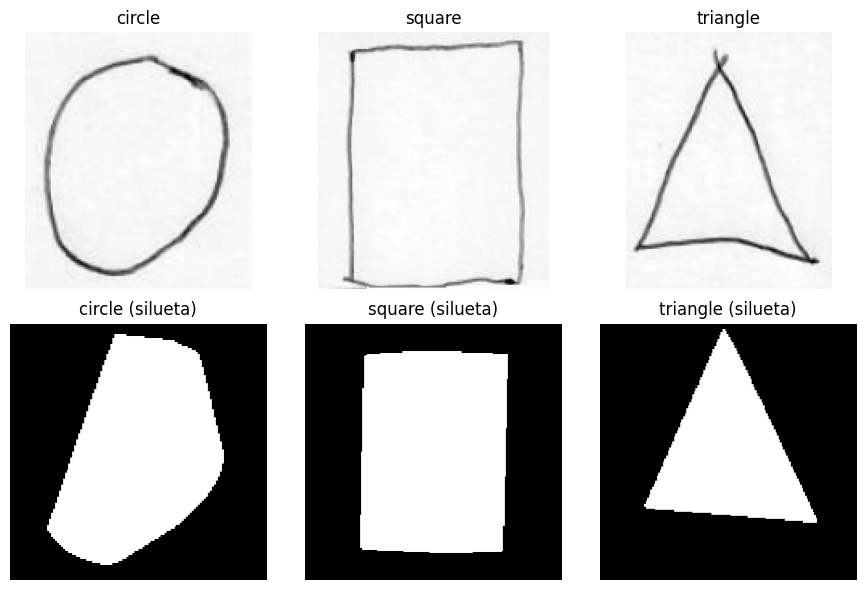

In [2]:
images, labels, class_names = load_ups_dataset()
labels = np.array(labels)
print(f'{len(images)} imágenes | clases: {class_names}')

fig, axes = plt.subplots(2, 3, figsize=(9, 6))
for c, name in enumerate(class_names):
    i = int(np.where(labels == c)[0][0])
    axes[0, c].imshow(images[i], cmap='gray'); axes[0, c].set_title(name); axes[0, c].axis('off')
    axes[1, c].imshow(filled_shape_mask(images[i]), cmap='gray')
    axes[1, c].set_title(f'{name} (silueta)'); axes[1, c].axis('off')
plt.tight_layout(); plt.show()


### 2. Inyección de ruido (Gaussiano y Salt & Pepper, 3 niveles)
Se estudia cómo el ruido degrada las características globales (Unidad 3).

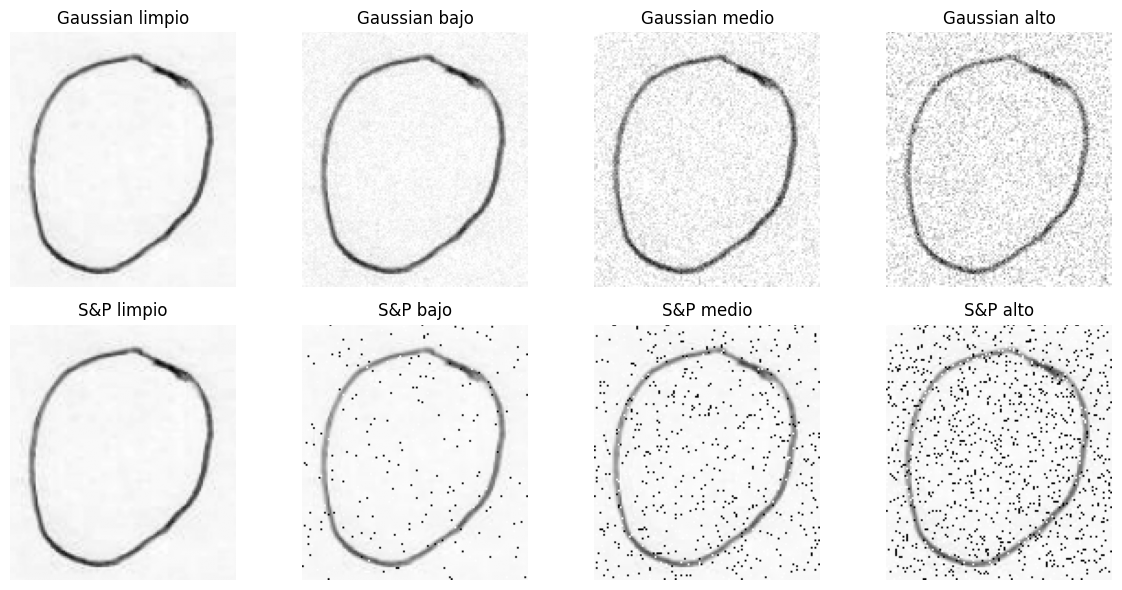

In [3]:
rng = np.random.default_rng(0)
i = int(np.where(labels == 0)[0][0])   # un círculo
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for col, level in enumerate(['limpio', 'bajo', 'medio', 'alto']):
    g = images[i] if level == 'limpio' else apply_noise(images[i], 'gaussian', level, rng)
    sp = images[i] if level == 'limpio' else apply_noise(images[i], 'salt_pepper', level, rng)
    axes[0, col].imshow(g, cmap='gray'); axes[0, col].set_title(f'Gaussian {level}'); axes[0, col].axis('off')
    axes[1, col].imshow(sp, cmap='gray'); axes[1, col].set_title(f'S&P {level}'); axes[1, col].axis('off')
plt.tight_layout(); plt.show()


### 3. Rotaciones aleatorias (0º–360º) — verificación de invarianza

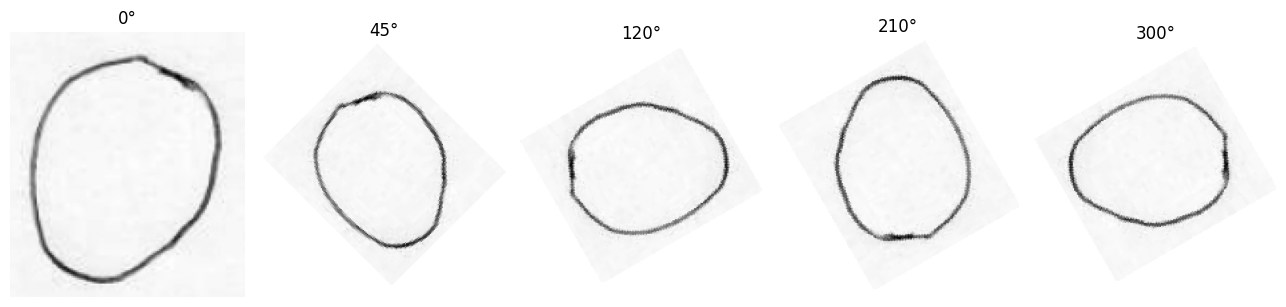

In [4]:
fig, axes = plt.subplots(1, 5, figsize=(13, 3))
for k, ang in enumerate([0, 45, 120, 210, 300]):
    axes[k].imshow(rotate(images[i], ang), cmap='gray')
    axes[k].set_title(f'{ang}°'); axes[k].axis('off')
plt.tight_layout(); plt.show()


### 4. Extracción de descriptores
Hu (7), Zernike n=8 (25 magnitudes) y Shape Signature (12 componentes).

In [5]:
d = extract_all(images[i])
for k, v in d.items():
    print(f'{k:16s} -> dim={len(v)}')


hu               -> dim=7
zernike          -> dim=25
shape_signature  -> dim=12


### 5. Clasificación por nivel de ruido (KNN, K = 7)
Para cada nivel se construye el conjunto aumentado (rotaciones + ruido), se
extraen los tres descriptores y se entrena un KNN. El split es **por grupos**
(las variantes de una misma imagen no se reparten entre train/test) para evitar
*data leakage*. Se reportan **matrices de confusión** y **accuracy**.

In [6]:
LEVELS = ['limpio', 'bajo', 'medio', 'alto']
NOISE = 'gaussian'    # cambia a 'salt_pepper' para el otro experimento

robustness = {d: {} for d in DESCRIPTOR_NAMES}
for level in LEVELS:
    X_by, y, groups = build_feature_set(images, list(labels), NOISE, level)
    gss = GroupShuffleSplit(n_splits=1, test_size=0.3, random_state=config.RANDOM_SEED)
    tr, te = next(gss.split(X_by['hu'], y, groups))
    for desc in DESCRIPTOR_NAMES:
        clf = build_classifier('knn'); clf.fit(X_by[desc][tr], y[tr])
        acc = accuracy_score(y[te], clf.predict(X_by[desc][te]))
        robustness[desc][level] = acc
    print(f'{level:7s} | ' + ' | '.join(f'{d}={robustness[d][level]:.3f}' for d in DESCRIPTOR_NAMES))


limpio  | hu=0.645 | zernike=0.822 | shape_signature=0.830


bajo    | hu=0.623 | zernike=0.822 | shape_signature=0.792


medio   | hu=0.606 | zernike=0.814 | shape_signature=0.848


alto    | hu=0.651 | zernike=0.842 | shape_signature=0.888


#### Matriz de confusión (ejemplo: nivel ALTO, Zernike)

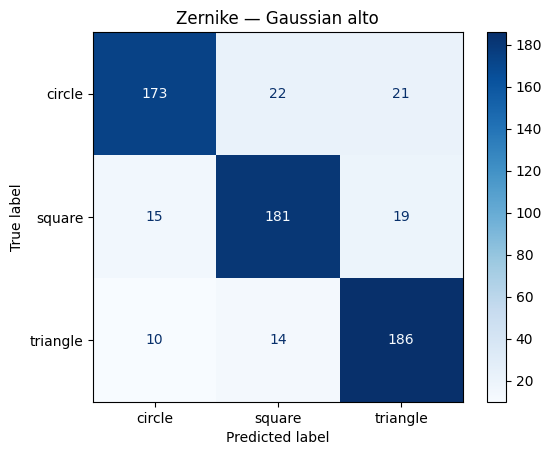

In [7]:
X_by, y, groups = build_feature_set(images, list(labels), NOISE, 'alto')
gss = GroupShuffleSplit(n_splits=1, test_size=0.3, random_state=config.RANDOM_SEED)
tr, te = next(gss.split(X_by['zernike'], y, groups))
clf = build_classifier('knn'); clf.fit(X_by['zernike'][tr], y[tr])
cm = confusion_matrix(y[te], clf.predict(X_by['zernike'][te]))
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(cmap='Blues')
plt.title('Zernike — Gaussian alto'); plt.show()


### 6. Curva de robustez y PCA

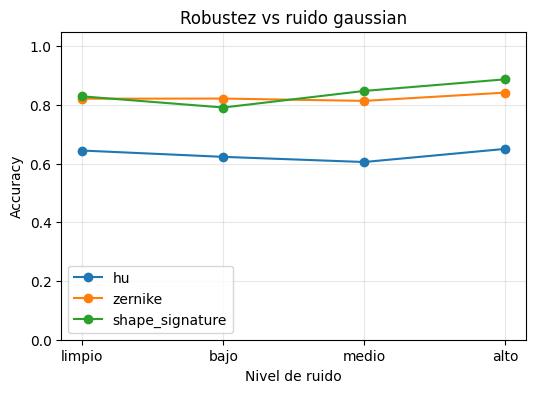

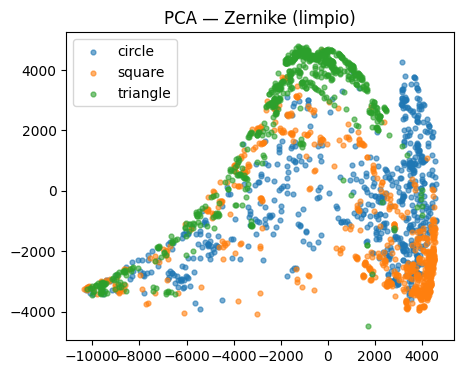

In [8]:
plt.figure(figsize=(6, 4))
for desc in DESCRIPTOR_NAMES:
    plt.plot(LEVELS, [robustness[desc][l] for l in LEVELS], marker='o', label=desc)
plt.ylim(0, 1.05); plt.grid(alpha=0.3); plt.xlabel('Nivel de ruido'); plt.ylabel('Accuracy')
plt.title(f'Robustez vs ruido {NOISE}'); plt.legend(); plt.show()

from sklearn.decomposition import PCA
X_by, y, _ = build_feature_set(images, list(labels), NOISE, 'limpio')
p = PCA(n_components=2).fit_transform(X_by['zernike'])
plt.figure(figsize=(5, 4))
for c, name in enumerate(class_names):
    m = y == c; plt.scatter(p[m, 0], p[m, 1], s=12, alpha=0.6, label=name)
plt.title('PCA — Zernike (limpio)'); plt.legend(); plt.show()


### 7. Conclusiones (alineadas con la guía)

- **Superioridad de la ortogonalidad:** los **Momentos de Zernike** mantienen una
  precisión alta y estable frente al ruido, mientras que los **Momentos de Hu**
  son los más sensibles (su accuracy es la más baja y la que más cae). Esto
  confirma que la base ortogonal de Zernike es menos redundante y más robusta.
- **Shape Signature** ofrece muy buena precisión porque trabaja sobre el contorno
  remuestreado y su firma espectral es naturalmente invariante a rotación/escala.
- **Degradación:** a mayor nivel de ruido, la calidad de la segmentación cae y con
  ella todos los descriptores; el filtro de mediana mitiga el ruido Salt & Pepper.
- El análisis **PCA** muestra cómo las tres clases forman clusters separables que el
  ruido tiende a mezclar.
